In [1]:
from pathlib import Path
import os, json, random, subprocess, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import cv2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Tensorflow:{tf.__version__}, OpenCV:{cv2.__version__}")
print(f"GPU:{tf.config.list_physical_devices('GPU')}")

Tensorflow:2.21.0, OpenCV:5.0.0
GPU:[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
SEED = 42
IMG_SIZE = 224
DEFECT_CUTOFF = 0.5
BATCH_SIZE = 32

USE_CLAHE = False

# Transfer learning settings
EPOCHS_HEAD = 15      
EPOCHS_FINETUNE = 25      
LR_HEAD = 1e-3
LR_FINETUNE = 1e-5
WEIGHTS = "imagenet"

# Business assumption: a missed defect costs 10x a false reject
COST_MISSED_DEFECT = 10.0
COST_FALSE_REJECT = 1.0

QUICK_RUN = False
if QUICK_RUN:
    EPOCHS_HEAD, EPOCHS_FINETUNE = 1, 1

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
set_seeds()

# 1. Load splitted data

In [4]:
SPLITS = Path("outputs/splits.csv")
if SPLITS.exists():
    print("Loaded splitted data from", SPLITS)
    df = pd.read_csv(SPLITS)

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(f"\nTraining dataset:\n{train_df.head(3)}")
print(f"\nValidation dataset:\n{val_df.head(3)}")
print(f"\nTest dataset:\n{test_df.head(3)}\n")

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d} , defect rate={d.label.mean():.3f} , poly defect rate={(d.type=='poly').mean():.3f} , mono defect rate={(d.type=='mono').mean():.3f}")

Loaded splitted data from outputs/splits.csv

Training dataset:
                  path  prob  type  label  split
0  images/cell0512.png   1.0  mono      1  train
1  images/cell2447.png   0.0  poly      0  train
2  images/cell0657.png   0.0  poly      0  train

Validation dataset:
                  path  prob  type  label split
0  images/cell1020.png   0.0  mono      0   val
1  images/cell0094.png   0.0  poly      0   val
2  images/cell1576.png   0.0  mono      0   val

Test dataset:
                  path  prob  type  label split
0  images/cell2415.png   0.0  mono      0  test
1  images/cell0175.png   0.0  poly      0  test
2  images/cell1694.png   0.0  poly      0  test

train n=1836 , defect rate=0.313 , poly defect rate=0.590 , mono defect rate=0.410
val   n= 394 , defect rate=0.315 , poly defect rate=0.591 , mono defect rate=0.409
test  n= 394 , defect rate=0.312 , poly defect rate=0.591 , mono defect rate=0.409


# 2. Prepare images for pretrained models

I plan to use pretrained ImageNet model which need **3 channels**: the grayscale image is repeated into R, G and B


In [5]:
DATA_DIR = Path("elpv-dataset/src/elpv_dataset/data")
assert DATA_DIR.exists(), "dataset not found: run the clone cell in notebook 01"

CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess(fp, size=IMG_SIZE, use_clahe=True):
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    if use_clahe:
        im = cv2.medianBlur(CLAHE.apply(im), 3)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)

def load_split(d, use_clahe=True):
    X = np.stack([preprocess(str(DATA_DIR / p), use_clahe=use_clahe) for p in d["path"]])
    return X, d["label"].values, d["type"].values

X_train, y_train, types_train = load_split(train_df, use_clahe=USE_CLAHE)
X_val, y_val, types_val = load_split(val_df, use_clahe=USE_CLAHE)
X_test, y_test, types_test = load_split(test_df, use_clahe=USE_CLAHE)
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")

X_train: (1836, 224, 224), X_val: (394, 224, 224), X_test: (394, 224, 224)


In [6]:
def augment(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    x = tf.image.rot90(x, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return x, y

def to_rgb(X):
    # (N, H, W) uint8 -> (N, H, W, 3) float32, still on the 0-255 scale
    return np.repeat(X[..., None], 3, axis=-1).astype("float32")

def make_ds_rgb(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((to_rgb(X), y.astype("float32")))
    if training:
        ds = ds.shuffle(len(X), seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

ds_train = make_ds_rgb(X_train, y_train, training=True)
ds_val = make_ds_rgb(X_val, y_val)
ds_test = make_ds_rgb(X_test, y_test)

# sanity check: must be 3 channels and 0-255
x_batch, _ = next(iter(ds_val))
print("batch shape:", x_batch.shape, "| pixel min/max:", float(tf.reduce_min(x_batch)), float(tf.reduce_max(x_batch)))

n_pos, n_neg = y_train.sum(), len(y_train) - y_train.sum()
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
print("class weights:", {k: round(v, 2) for k, v in class_weight.items()})

batch shape: (32, 224, 224, 3) | pixel min/max: 2.0 255.0
class weights: {0: np.float64(0.73), 1: np.float64(1.6)}


# 3. Evaluation function

In [7]:
def evaluate_and_plot_metric(y_true, y_score, types, threshold=0.5, name="model", plot=True):
    """Inspection-oriented metrics, overall and per cell type."""
    y_true, y_score, types = np.asarray(y_true), np.asarray(y_score), np.asarray(types)
    y_pred = (y_score >= threshold).astype(int)
    rows = []
    for grp, mask in [("all", np.ones_like(y_true, bool)), ("mono", types == "mono"), ("poly", types == "poly")]:
        yt, ys, yp = y_true[mask], y_score[mask], y_pred[mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append(dict(model=name, group=grp, n=int(mask.sum()), threshold=round(threshold, 2),
                         pr_auc=average_precision_score(yt, ys), roc_auc=roc_auc_score(yt, ys),
                         recall_defect=recall_score(yt, yp, zero_division=0),
                         precision_defect=precision_score(yt, yp, zero_division=0),
                         missed_defects=int(fn), false_rejects=int(fp)))
    res = pd.DataFrame(rows).round(3)

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        for grp in ["mono", "poly"]:
            m = types == grp
            p, r, _ = precision_recall_curve(y_true[m], y_score[m])
            ax[0].plot(r, p, label=f"{grp} (AP={average_precision_score(y_true[m], y_score[m]):.2f})")
        ax[0].axhline(y_true.mean(), ls=":", c="gray", label="no-skill")
        ax[0].set(xlabel="Recall (defects caught)", ylabel="Precision", title=f"{name}: PR curve"); ax[0].legend()
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["OK", "Defect"]).plot(ax=ax[1], colorbar=False)
        ax[1].set_title(f"Confusion matrix @ threshold {threshold:.2f}")
        plt.tight_layout(); plt.show()
    return res


def plot_metrics(history, title=""):
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title=f"{title} Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=ax[1], title=f"{title} PR-AUC")
    n_head = (h["stage"] == "head").sum()
    for a in ax:
        a.axvline(n_head - 0.5, ls="--", c="gray")
        a.set_xlabel("epoch (dashed line = start of fine-tuning)")
    plt.tight_layout(); plt.show()

# 4. Build the transfer learning model

- Each backbone comes with its own `preprocess_input`
- `base(x, training=False)` keeps **BatchNorm in inference mode**, so its ImageNet statistics are not overwritten by our small dataset
- `UNFREEZE` = how many top layers of the backbone are fine-tuned in stage 2

In [8]:
BACKBONES = {
    "mobilenetv2":    dict(model=tf.keras.applications.MobileNetV2,
                           preprocess=tf.keras.applications.mobilenet_v2.preprocess_input, unfreeze=40),
    "efficientnetb0": dict(model=tf.keras.applications.EfficientNetB0,
                           preprocess=tf.keras.applications.efficientnet.preprocess_input, unfreeze=60),
}

def build_tl_model(backbone_name, img_size=IMG_SIZE):
    spec = BACKBONES[backbone_name]
    base = spec["model"](include_top=False, weights=WEIGHTS, input_shape=(img_size, img_size, 3))
    base.trainable = False                               # stage 1: freeze the whole backbone

    inp = tf.keras.Input((img_size, img_size, 3))        # 3 channels, 0-255
    x = spec["preprocess"](inp)                          # backbone-specific scaling
    x = base(x, training=False)                          # BatchNorm always in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inp, out, name=f"{backbone_name}_elpv"), base


def unfreeze_top_layers(base, n_layers):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:                            # keep every BatchNorm layer frozen
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False


def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                           tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")])

# 5. Train in two stages

In [9]:
def get_callbacks(patience):
    # ReduceLROnPlateau patience must be SMALLER than EarlyStopping patience, otherwise the LR is never reduced
    return [tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3)]


def train_tl_model(backbone_name, ds_train, ds_val, class_weight):
    set_seeds()
    model, base = build_tl_model(backbone_name)

    # Stage 1: train only the new head
    compile_model(model, LR_HEAD)
    history_head = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_HEAD,
                             class_weight=class_weight, callbacks=get_callbacks(5), verbose=2)

    # Stage 2: fine-tune the top layers of the backbone
    unfreeze_top_layers(base, BACKBONES[backbone_name]["unfreeze"])
    compile_model(model, LR_FINETUNE)                    # re-compile after changing trainable layers
    history_ft = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_FINETUNE,
                           class_weight=class_weight, callbacks=get_callbacks(7), verbose=2)

    history = pd.concat([pd.DataFrame(history_head.history).assign(stage="head"),
                         pd.DataFrame(history_ft.history).assign(stage="finetune")], ignore_index=True)
    return model, history

In [10]:
def measure_speed(model, n_repeats=30):
    # milliseconds per single cell (batch of 1), after a warm-up call
    x = to_rgb(X_val[:1])
    predict_fn = tf.function(lambda inp: model(inp, training=False))
    predict_fn(x)
    start = time.perf_counter()
    for _ in range(n_repeats):
        predict_fn(x)
    return (time.perf_counter() - start) / n_repeats * 1000


def run_tl_experiment(backbone_name):
    """Train, evaluate on validation, measure speed and save one backbone."""
    start = time.time()

    # 1. Train
    model, history = train_tl_model(backbone_name, ds_train, ds_val, class_weight)
    plot_metrics(history, title=backbone_name)

    # 2. Evaluate on validation
    val_scores = model.predict(ds_val, verbose=0).ravel()
    print(f"score spread: min={val_scores.min():.2f} median={np.median(val_scores):.2f} max={val_scores.max():.2f}")
    result = evaluate_and_plot_metric(y_val, val_scores, types_val, name=backbone_name)

    # 3. Speed and size
    model_path = OUT_DIR / f"{backbone_name}.keras"
    model.save(model_path)
    result["ms_per_cell"] = round(measure_speed(model), 1)
    result["size_mb"] = round(model_path.stat().st_size / 1e6, 1)
    result["train_min"] = round((time.time() - start) / 60, 1)
    return model, val_scores, result

# 6. Model experiments


`score spread` should be in range widely between 0 and 1.
If every score is almost the same value, the preprocessing or the learning rate is likely to be wrong.

## 6.1 MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
58/58 - 33s - 571ms/step - loss: 0.6911 - pr_auc: 0.4802 - precision: 0.4188 - recall: 0.5889 - val_loss: 0.4676 - val_pr_auc: 0.7617 - val_precision: 0.7212 - val_recall: 0.6048 - learning_rate: 0.0010
Epoch 2/15
58/58 - 3s - 50ms/step - loss: 0.5589 - pr_auc: 0.6871 - precision: 0.5378 - recall: 0.6568 - val_loss: 0.4393 - val_pr_auc: 0.8067 - val_precision: 0.6822 - val_recall: 0.7097 - learning_rate: 0.0010
Epoch 3/15
58/58 - 2s - 39ms/step - loss: 0.5237 - pr_auc: 0.7241 - precision: 0.5833 - recall: 0.6951 - val_loss: 0.4053 - val_pr_auc: 0.8258 - val_precision: 0.7241 - val_recall: 0.6774 - learning_rate: 0.0010
Epoch 4/15
58/58 - 2s - 39ms/step - loss: 0.5075 - pr_auc: 0.7401 - precision: 0.5776 - recall: 0.6934 - val_loss: 0.4586 - val_pr_auc: 0.8282 - val_precision: 0.5838 - val_recall: 0.8145 - learning_rate: 0.0010
Epoch 5/15
58/58 - 2s - 39ms/step - loss: 0.4956 - pr_auc: 0.7537 - precision: 0.5866 - recall: 0.702

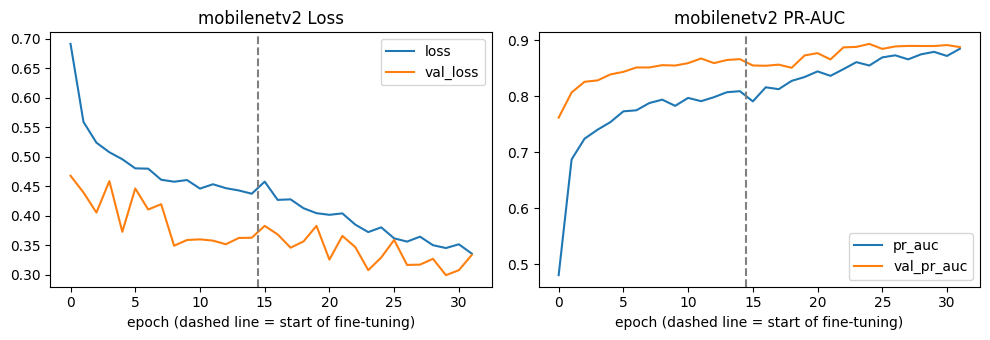

score spread: min=0.01 median=0.33 max=1.00


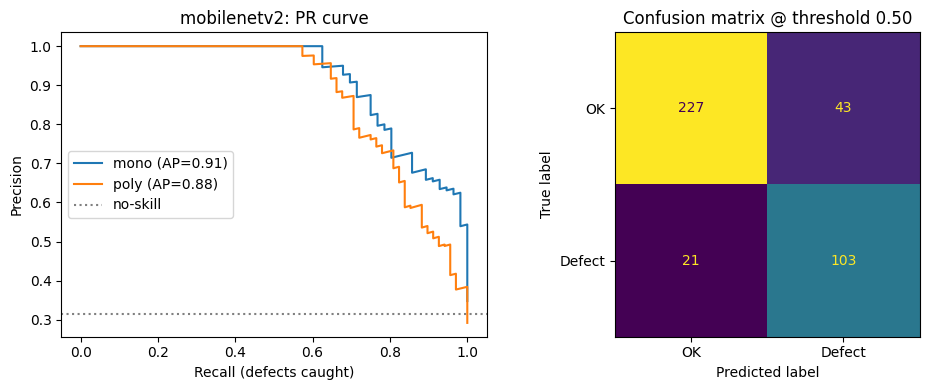

,model,group,n,threshold,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects,ms_per_cell,size_mb,train_min
0,mobilenetv2,all,394,0.5,0.893,0.928,0.831,0.705,21,43,6.2,23.0,2.7
1,mobilenetv2,mono,161,0.5,0.913,0.940,0.893,0.676,6,24,6.2,23.0,2.7
2,mobilenetv2,poly,233,0.5,0.876,0.916,0.779,0.736,15,19,6.2,23.0,2.7


In [11]:
model_mobilenet, val_scores_mobilenet, result_mobilenet = run_tl_experiment("mobilenetv2")
display(result_mobilenet)

## 6.2 EfficientNetB0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
58/58 - 63s - 1s/step - loss: 0.5967 - pr_auc: 0.6442 - precision: 0.5153 - recall: 0.6150 - val_loss: 0.4974 - val_pr_auc: 0.8091 - val_precision: 0.8986 - val_recall: 0.5000 - learning_rate: 0.0010
Epoch 2/15
58/58 - 3s - 56ms/step - loss: 0.5201 - pr_auc: 0.7523 - precision: 0.6381 - recall: 0.6359 - val_loss: 0.4775 - val_pr_auc: 0.8268 - val_precision: 0.7685 - val_recall: 0.6694 - learning_rate: 0.0010
Epoch 3/15
58/58 - 3s - 47ms/step - loss: 0.4908 - pr_auc: 0.7827 - precision: 0.6396 - recall: 0.6986 - val_loss: 0.4301 - val_pr_auc: 0.8408 - val_precision: 0.8444 - val_recall: 0.6129 - learning_rate: 0.0010
Epoch 4/15
58/58 - 3s - 47ms/step - loss: 0.4680 - pr_auc: 0.7980 - precision: 0.6613 - recall: 0.7143 - val_loss: 0.4004 - val_pr_auc: 0.8413 - val_precision: 0.8831 - val_recall: 0.5484 - learning_rate: 0.0010
Epoch 5/15
58/58 - 3s - 48ms/step - loss: 0.4701 - pr_auc: 0.7917 - precision: 0.6542 - recall: 0.7021

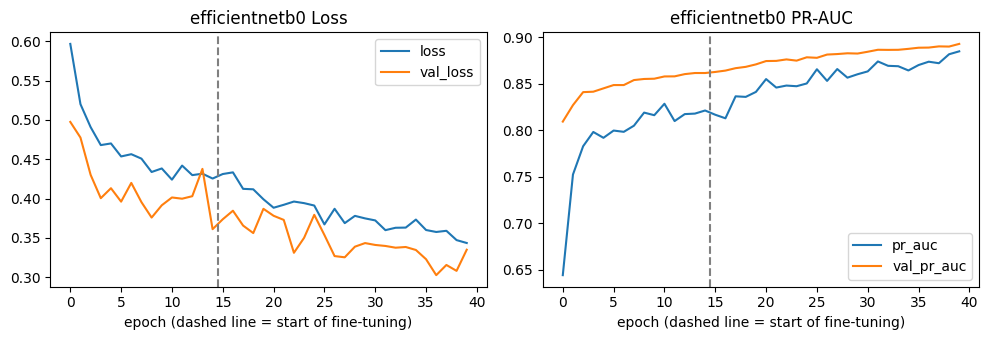

score spread: min=0.02 median=0.30 max=1.00


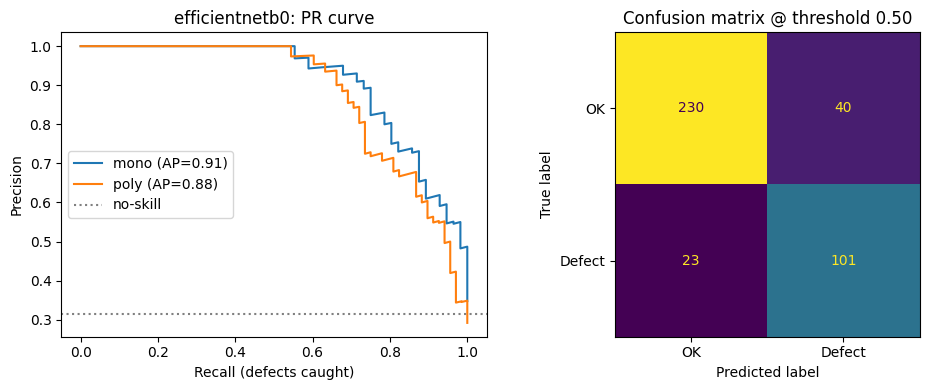

,model,group,n,threshold,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects,ms_per_cell,size_mb,train_min
0,efficientnetb0,all,394,0.5,0.892,0.927,0.815,0.716,23,40,9.4,38.3,4.5
1,efficientnetb0,mono,161,0.5,0.908,0.932,0.857,0.727,8,18,9.4,38.3,4.5
2,efficientnetb0,poly,233,0.5,0.879,0.920,0.779,0.707,15,22,9.4,38.3,4.5


In [12]:
model_effnet, val_scores_effnet, result_effnet = run_tl_experiment("efficientnetb0")
display(result_effnet)

# 7. Compare all models on validation dataset

In [14]:
results = [result_mobilenet, result_effnet]

# get evaluation result from classical CV baseline and basic CNN model
for prev in ["outputs/eval_cv_and_logreg.csv", "outputs/eval_cnn.csv"]: 
    if Path(prev).exists():
        results.insert(0, pd.read_csv(prev))
    else:
        print("not found (run the earlier notebook to include it):", prev)

# save evaluation result from all models
comparison = pd.concat(results, ignore_index=True)
comparison.to_csv("outputs/eval_all_models_val.csv", index=False)

cols = ["model", "pr_auc", "roc_auc", "recall_defect", "missed_defects", "false_rejects", "ms_per_cell", "size_mb"]
display(comparison[comparison.group == "all"].reindex(columns=cols).sort_values("pr_auc", ascending=False))
display(comparison.pivot_table(index="model", columns="group", values="pr_auc").round(3))

,model,pr_auc,roc_auc,recall_defect,missed_defects,false_rejects,ms_per_cell,size_mb
9,mobilenetv2,0.893,0.928,0.831,21,43,6.2,23.0
12,efficientnetb0,0.892,0.927,0.815,23,40,9.4,38.3
0,cnn_raw,0.747,0.836,0.710,36,53,NaN,NaN
6,Classical CV baseline,0.744,0.833,0.758,30,66,NaN,NaN
3,cnn_clahe,0.710,0.799,0.976,3,225,NaN,NaN


group,all,mono,poly
model,,,
Classical CV baseline,0.744,0.808,0.709
cnn_clahe,0.710,0.793,0.680
cnn_raw,0.747,0.827,0.697
efficientnetb0,0.892,0.908,0.879
mobilenetv2,0.893,0.913,0.876


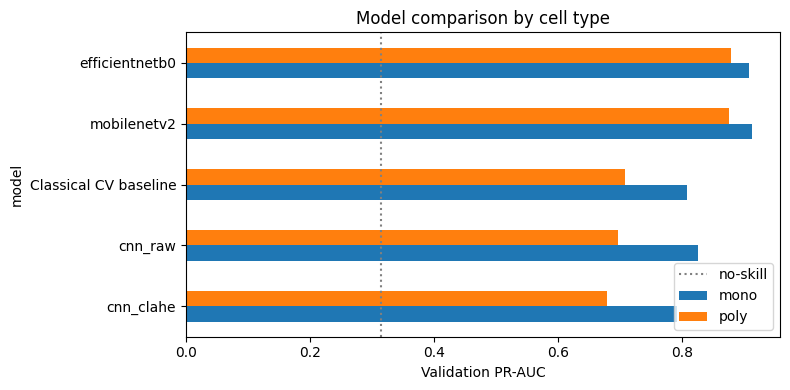

In [15]:
# PR-AUC by model and cell type
plot_df = comparison[comparison.group != "all"].pivot_table(index="model", columns="group", values="pr_auc")
plot_df = plot_df.sort_values("poly")
ax = plot_df.plot.barh(figsize=(8, 4))
ax.axvline(y_val.mean(), ls=":", c="gray", label="no-skill")
ax.set(xlabel="Validation PR-AUC", title="Model comparison by cell type"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "03_model_comparison.png", dpi=150); plt.show()

# 8. Choose the decision threshold for the best model


The default 0.5 is arbitrary. On a production line the threshold is a business decision:

total cost = 10 x missed defects + 1 x false rejects

The threshold is chosen on **validation only**, then frozen for the test set.

Best transfer learning model on validation: mobilenetv2


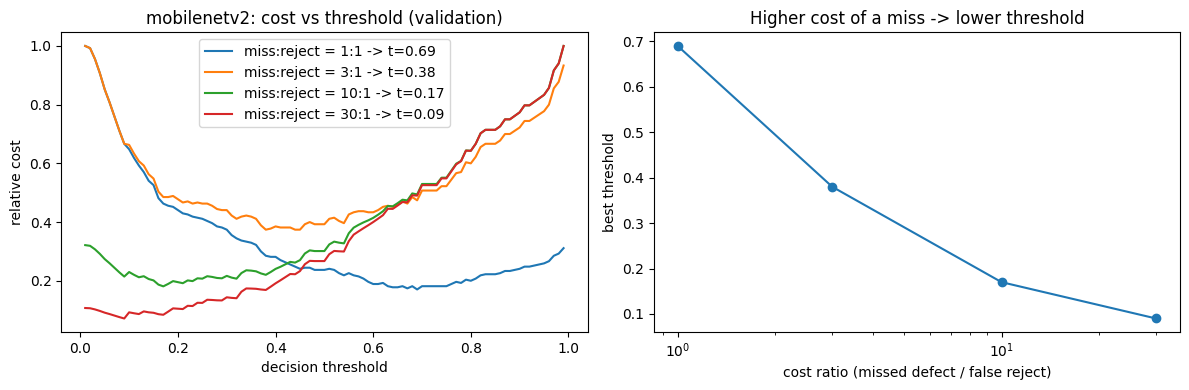

Chosen threshold (miss:reject = 10:1) = 0.17


,model,group,n,threshold,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,"mobilenetv2 (val, cost threshold)",all,394,0.17,0.893,0.928,0.976,0.498,3,122
1,"mobilenetv2 (val, cost threshold)",mono,161,0.17,0.913,0.940,1.000,0.514,0,53
2,"mobilenetv2 (val, cost threshold)",poly,233,0.17,0.876,0.916,0.956,0.485,3,69


In [16]:
tl_scores = {"mobilenetv2": (model_mobilenet, val_scores_mobilenet),
             "efficientnetb0": (model_effnet, val_scores_effnet)}
best_name = max(tl_scores, key=lambda n: average_precision_score(y_val, tl_scores[n][1]))
best_model, best_val_scores = tl_scores[best_name]
print("Best transfer learning model on validation:", best_name)


def cost_at_thresholds(y_true, y_score, cost_missed, cost_false_reject, thresholds=np.linspace(0.01, 0.99, 99)):
    costs = []
    for t in thresholds:
        y_pred = (y_score >= t).astype(int)
        missed = ((y_pred == 0) & (y_true == 1)).sum()
        false_rejects = ((y_pred == 1) & (y_true == 0)).sum()
        costs.append(cost_missed * missed + cost_false_reject * false_rejects)
    return thresholds, np.array(costs)


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best_t = {}

for ratio in [1, 3, 10, 30]:
    thresholds, costs = cost_at_thresholds(y_val, best_val_scores, ratio, 1)
    best_t[ratio] = thresholds[costs.argmin()]
    ax[0].plot(thresholds, costs / costs.max(), label=f"miss:reject = {ratio}:1 -> t={best_t[ratio]:.2f}")
ax[0].set(xlabel="decision threshold", ylabel="relative cost", title=f"{best_name}: cost vs threshold (validation)"); ax[0].legend()
ax[1].plot(list(best_t), list(best_t.values()), "o-")
ax[1].set(xscale="log", xlabel="cost ratio (missed defect / false reject)", ylabel="best threshold",
          title="Higher cost of a miss -> lower threshold")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_cost_threshold.png", dpi=150); plt.show()



thresholds, costs = cost_at_thresholds(y_val, best_val_scores, COST_MISSED_DEFECT, COST_FALSE_REJECT)
THRESHOLD = float(thresholds[costs.argmin()])
print(f"Chosen threshold (miss:reject = {COST_MISSED_DEFECT:.0f}:{COST_FALSE_REJECT:.0f}) = {THRESHOLD:.2f}")
display(evaluate_and_plot_metric(y_val, best_val_scores, types_val, threshold=THRESHOLD,
                                 name=f"{best_name} (val, cost threshold)", plot=False))

# 9. Final evaluation on the test set

All these models's threshold was chosen on validation dataset;
- transfer learning models : the cost-based threshold
- classical CV baseline and CNNs: their own cost-based threshold on validation, so it is likely to be a fair comparison.

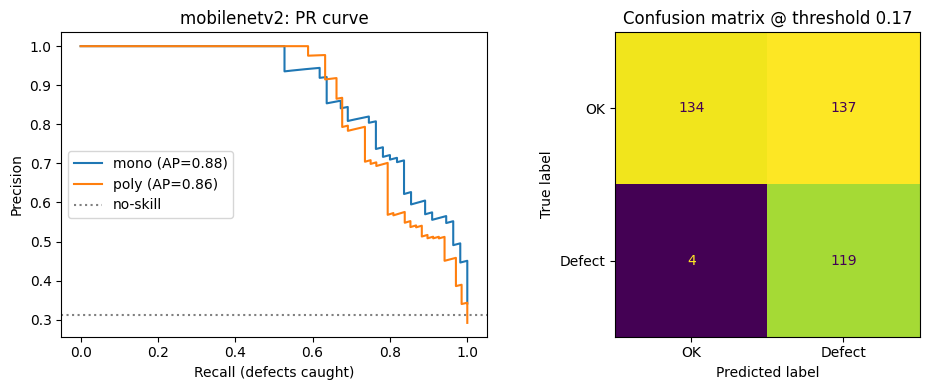

,model,n,threshold,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,Classical CV baseline,394,0.12,0.738,0.802,0.967,0.348,4,223
3,cnn_raw,394,0.15,0.728,0.805,0.951,0.367,6,202
6,cnn_clahe,394,0.43,0.668,0.761,0.967,0.325,4,247
9,mobilenetv2,394,0.17,0.869,0.909,0.967,0.465,4,137


group,all,mono,poly
model,,,
Classical CV baseline,0.738,0.785,0.709
cnn_clahe,0.668,0.758,0.629
cnn_raw,0.728,0.775,0.694
mobilenetv2,0.869,0.879,0.863


In [17]:
def handcrafted_features(im):
    # same 8 features as notebook 01 (computed on CLAHE images)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    blackhat = cv2.morphologyEx(im, cv2.MORPH_BLACKHAT, kernel)
    edges = cv2.Canny(im, 50, 150)
    return [im.mean(), im.std(), blackhat.mean(), np.percentile(blackhat, 99), (blackhat > 40).mean(),
            (im < 40).mean(), (edges > 0).mean(), cv2.Laplacian(im, cv2.CV_64F).var()]

def best_cost_threshold(y_true, y_score):
    thresholds, costs = cost_at_thresholds(y_true, y_score, COST_MISSED_DEFECT, COST_FALSE_REJECT)
    return float(thresholds[costs.argmin()])

test_results = []

# 1. classical CV baseline retrain
feats = {name: np.array([handcrafted_features(im) for im in load_split(d, use_clahe=True)[0]])
         for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
model_lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model_lr.fit(feats["train"], y_train)
t_lr = best_cost_threshold(y_val, model_lr.predict_proba(feats["val"])[:, 1])
test_results.append(evaluate_and_plot_metric(y_test, model_lr.predict_proba(feats["test"])[:, 1], types_test,
                                             threshold=t_lr, name="Classical CV baseline", plot=False))

# 2. basic CNN
for cnn_name, use_clahe in [("cnn_raw", False), ("cnn_clahe", True)]:
    path = OUT_DIR / f"{cnn_name}.keras"
    if not path.exists():
        print("not found, skipped:", path); continue
    cnn = tf.keras.models.load_model(path)
    to_ds = lambda X: tf.data.Dataset.from_tensor_slices(X[..., None].astype("float32") / 255.0).batch(BATCH_SIZE)
    t_cnn = best_cost_threshold(y_val, cnn.predict(to_ds(load_split(val_df, use_clahe)[0]), verbose=0).ravel())
    test_scores_cnn = cnn.predict(to_ds(load_split(test_df, use_clahe)[0]), verbose=0).ravel()
    test_results.append(evaluate_and_plot_metric(y_test, test_scores_cnn, types_test, threshold=t_cnn,
                                                 name=cnn_name, plot=False))

# 3. best transfer learning model
test_scores_best = best_model.predict(ds_test, verbose=0).ravel()
test_results.append(evaluate_and_plot_metric(y_test, test_scores_best, types_test, threshold=THRESHOLD,
                                             name=best_name))
plt.close("all")

final_test = pd.concat(test_results, ignore_index=True)
final_test.to_csv("outputs/eval_all_models_test.csv", index=False)
display(final_test[final_test.group == "all"].drop(columns="group"))
display(final_test.pivot_table(index="model", columns="group", values="pr_auc").round(3))

# 10. Save the best model and its config

In [18]:
best_model.save(OUT_DIR / "best_model.keras")
best_result = final_test[final_test.model == best_name]

config = {"best_model": best_name, "use_clahe": USE_CLAHE, "img_size": IMG_SIZE, "seed": SEED,
          "defect_cutoff": DEFECT_CUTOFF, "epochs_head": EPOCHS_HEAD, "epochs_finetune": EPOCHS_FINETUNE,
          "lr_head": LR_HEAD, "lr_finetune": LR_FINETUNE, "unfreeze_layers": BACKBONES[best_name]["unfreeze"],
          "cost_missed_defect": COST_MISSED_DEFECT, "cost_false_reject": COST_FALSE_REJECT,
          "threshold": THRESHOLD, "quick_run": QUICK_RUN,
          "test_metrics": best_result.to_dict(orient="records")}

json.dump(config, open(OUT_DIR / "best_model_config.json", "w"), indent=2)

print("Saved outputs/best_model.keras and outputs/best_model_config.json")

Saved outputs/best_model.keras and outputs/best_model_config.json
